# 순환 신경망으로 IMDB 리뷰 분류하기

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # 데이터셋 로딩에만 keras 사용 (TensorFlow 불필요)

import random
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

import keras  # imdb 데이터 로딩 전용

### 환경/시드

In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')   # GPU PC / CPU 노트북 공용
print(device)

cpu


### 데이터

In [3]:
(train_input, train_target), (test_input, test_target) = keras.datasets.imdb.load_data(num_words=200)
print(train_input.shape, train_target.shape)
print(test_input.shape, test_target.shape)

print([len(x) for x in train_input[:20]])
print(train_target[:20])

train_input, val_input, train_target, val_target = train_test_split(
    train_input, train_target, test_size=0.2, random_state=42
)
print(train_input.shape, train_target.shape)
print(val_input.shape, val_target.shape)

lengths = np.array([len(x) for x in train_input])
print(np.mean(lengths))
print(np.median(lengths))

(25000,) (25000,)
(25000,) (25000,)
[218, 189, 141, 550, 147, 43, 123, 562, 233, 130, 450, 99, 117, 238, 109, 129, 163, 752, 212, 177]
[1 0 0 1 0 0 1 0 1 0 1 0 0 0 0 0 1 1 0 1]
(20000,) (20000,)
(5000,) (5000,)
239.00925
178.0


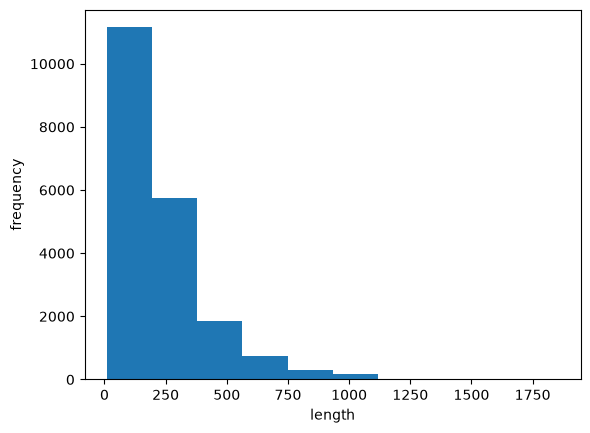

In [4]:
plt.hist(lengths)
plt.xlabel('length')
plt.ylabel('frequency')
plt.show()

### keras pad_sequences 기본 동작(padding='pre', truncating='pre')과 동일

In [5]:
def pad_sequences(seqs, maxlen):
    out = np.zeros((len(seqs), maxlen), dtype=np.int64)
    for i, s in enumerate(seqs):
        s = s[-maxlen:]
        if len(s) > 0:
            out[i, -len(s):] = s
    return out

train_seq = pad_sequences(train_input, maxlen=100)
print(train_seq.shape)
print(train_seq[0])
print(train_seq[0][-10:])

val_seq = pad_sequences(val_input, maxlen=100)
print(val_seq.shape)
print(val_seq[0])
print(val_seq[0][-10:])

train_x = torch.from_numpy(train_seq)
val_x = torch.from_numpy(val_seq)
train_y = torch.from_numpy(train_target).float()
val_y = torch.from_numpy(val_target).float()

(20000, 100)
[ 10   4  20   9   2   2   2   5  45   6   2   2  33   2   8   2 142   2
   5   2  17  73  17   2   5   2  19  55   2   2  92  66 104  14  20  93
  76   2 151  33   4  58  12 188   2 151  12   2  69   2 142  73   2   6
   2   7   2   2 188   2 103  14  31  10  10   2   7   2   5   2  80  91
   2  30   2  34  14  20 151  50  26 131  49   2  84  46  50  37  80  79
   6   2  46   7  14  20  10  10   2 158]
[  6   2  46   7  14  20  10  10   2 158]
(5000, 100)
[ 32   2   2   6   2   2   2   4   2   2   7  14  22  15 100  28   2  11
   4   2   7   6   2   2   2   2  51  75 130  56  19   9   2   2 105   2
   2   2 186   8  30   8 168   2  33   4   2   8  97   4   2   2  53   2
   6   2   2  38   2   2  17   8   2   4   2   2  46   4   2   5   2   2
   2  15   2 117  53  74  11  31   2  35  23   2   2  34 167   2  14   9
   2  22   2  11   2   2   2  14  58   2]
[ 2 22  2 11  2  2  2 14 58  2]


### 학습 유틸

In [6]:
def fit(model, train_x, train_y, val_x, val_y, ckpt_path,
        epochs=100, batch_size=64, lr=1e-4, patience=3):
    model.to(device)

    optimizer = torch.optim.RMSprop(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()      # sigmoid + binary_crossentropy

    train_loader = DataLoader(TensorDataset(train_x, train_y), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(val_x, val_y), batch_size=batch_size)

    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_val_loss, best_state, wait, stopped_epoch = float('inf'), None, 0, 0

    for epoch in range(epochs):
        # train
        model.train()
        total_loss, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += ((logits > 0).float() == yb).sum().item()
            n += len(yb)
        history['loss'].append(total_loss / n)
        history['accuracy'].append(correct / n)

        # validation
        model.eval()
        total_loss, correct, n = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                total_loss += criterion(logits, yb).item() * len(yb)
                correct += ((logits > 0).float() == yb).sum().item()
                n += len(yb)
        val_loss = total_loss / n
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(correct / n)

        print(f"Epoch {epoch+1}/{epochs} - loss: {history['loss'][-1]:.4f} - acc: {history['accuracy'][-1]:.4f} "
              f"- val_loss: {val_loss:.4f} - val_acc: {history['val_accuracy'][-1]:.4f}")

        # ModelCheckpoint(save_best_only) + EarlyStopping(restore_best_weights)
        if val_loss < best_val_loss:
            best_val_loss, wait = val_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, ckpt_path)
        else:
            wait += 1
            if wait >= patience:
                stopped_epoch = epoch
                break

    model.load_state_dict(best_state)
    return history, stopped_epoch

def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].plot(history['accuracy'])
    axes[0].plot(history['val_accuracy'])
    axes[0].set_xlabel('epoch')
    axes[0].set_ylabel('accuracy')
    axes[0].legend(['train', 'val'])

    axes[1].plot(history['loss'])
    axes[1].plot(history['val_loss'])
    axes[1].set_xlabel('epoch')
    axes[1].set_ylabel('loss')
    axes[1].legend(['train', 'val'])

    plt.show()

def summary(model):
    print(model)
    print('params:', sum(p.numel() for p in model.parameters()))

### 모델 1: one-hot + SimpleRNN

In [7]:
class OneHotRNN(nn.Module):
    def __init__(self, vocab_size=200, hidden=8):
        super().__init__()
        self.vocab_size = vocab_size
        self.rnn = nn.RNN(vocab_size, hidden, batch_first=True)   # tanh, 마지막 hidden state 사용
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):                                  # x: (B, 100) int64
        x = F.one_hot(x, self.vocab_size).float()          # (B, 100, 200) - 배치마다 변환해서 메모리 절약
        _, h = self.rnn(x)                                 # h: (1, B, 8)
        return self.fc(h[-1]).squeeze(-1)                  # logits (sigmoid는 loss에 포함)

model = OneHotRNN()
summary(model)     # 1,680 = 200*8 + 8*8 + 8 + 8 (PyTorch RNN은 bias가 2개) + fc 9

history, stopped_epoch = fit(model, train_x, train_y, val_x, val_y,
                             ckpt_path='./best-simplernn-model.pt')
print(stopped_epoch)

OneHotRNN(
  (rnn): RNN(200, 8, batch_first=True)
  (fc): Linear(in_features=8, out_features=1, bias=True)
)
params: 1689
Epoch 1/100 - loss: 0.6998 - acc: 0.5028 - val_loss: 0.6984 - val_acc: 0.4852
Epoch 2/100 - loss: 0.6947 - acc: 0.5031 - val_loss: 0.6949 - val_acc: 0.4864
Epoch 3/100 - loss: 0.6935 - acc: 0.5024 - val_loss: 0.6938 - val_acc: 0.5052
Epoch 4/100 - loss: 0.6930 - acc: 0.5040 - val_loss: 0.6932 - val_acc: 0.5054
Epoch 5/100 - loss: 0.6926 - acc: 0.5079 - val_loss: 0.6929 - val_acc: 0.5096
Epoch 6/100 - loss: 0.6923 - acc: 0.5107 - val_loss: 0.6927 - val_acc: 0.5136
Epoch 7/100 - loss: 0.6920 - acc: 0.5134 - val_loss: 0.6922 - val_acc: 0.5116
Epoch 8/100 - loss: 0.6916 - acc: 0.5199 - val_loss: 0.6920 - val_acc: 0.5154
Epoch 9/100 - loss: 0.6913 - acc: 0.5201 - val_loss: 0.6916 - val_acc: 0.5200
Epoch 10/100 - loss: 0.6909 - acc: 0.5276 - val_loss: 0.6914 - val_acc: 0.5236
Epoch 11/100 - loss: 0.6906 - acc: 0.5277 - val_loss: 0.6910 - val_acc: 0.5284
Epoch 12/100 - los

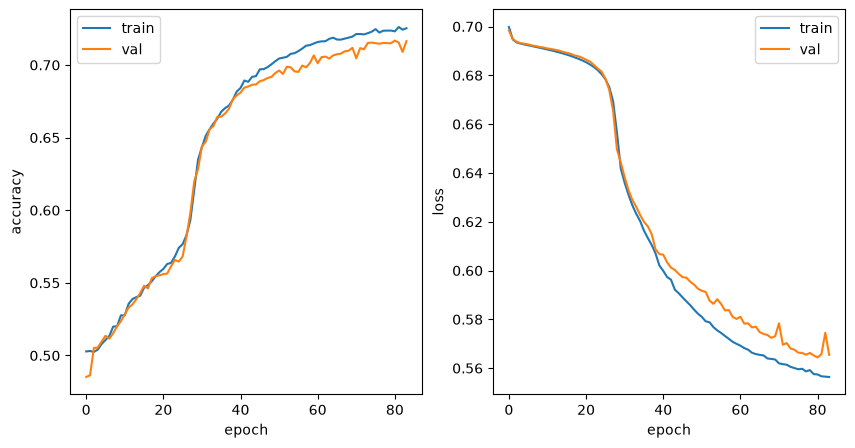

In [8]:
plot_history(history)

### 모델 2: Embedding + SimpleRNN

In [9]:
class EmbeddingRNN(nn.Module):
    def __init__(self, vocab_size=200, embed_dim=16, hidden=8):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)   # 3,200 = 200 * 16
        self.rnn = nn.RNN(embed_dim, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):                                  # x: (B, 100)
        x = self.embedding(x)                              # (B, 100, 16)
        _, h = self.rnn(x)
        return self.fc(h[-1]).squeeze(-1)

model_embedding = EmbeddingRNN()
summary(model_embedding)

history, stopped_epoch = fit(model_embedding, train_x, train_y, val_x, val_y,
                             ckpt_path='./best-embedding-model.pt')
print(stopped_epoch)

EmbeddingRNN(
  (embedding): Embedding(200, 16)
  (rnn): RNN(16, 8, batch_first=True)
  (fc): Linear(in_features=8, out_features=1, bias=True)
)
params: 3417
Epoch 1/100 - loss: 0.7026 - acc: 0.5006 - val_loss: 0.7018 - val_acc: 0.5030
Epoch 2/100 - loss: 0.6993 - acc: 0.5039 - val_loss: 0.7000 - val_acc: 0.4926
Epoch 3/100 - loss: 0.6973 - acc: 0.5092 - val_loss: 0.6985 - val_acc: 0.4948
Epoch 4/100 - loss: 0.6958 - acc: 0.5120 - val_loss: 0.6973 - val_acc: 0.4966
Epoch 5/100 - loss: 0.6946 - acc: 0.5113 - val_loss: 0.6964 - val_acc: 0.5014
Epoch 6/100 - loss: 0.6936 - acc: 0.5123 - val_loss: 0.6955 - val_acc: 0.5014
Epoch 7/100 - loss: 0.6928 - acc: 0.5161 - val_loss: 0.6948 - val_acc: 0.5002
Epoch 8/100 - loss: 0.6921 - acc: 0.5145 - val_loss: 0.6942 - val_acc: 0.5020
Epoch 9/100 - loss: 0.6916 - acc: 0.5161 - val_loss: 0.6937 - val_acc: 0.5014
Epoch 10/100 - loss: 0.6911 - acc: 0.5186 - val_loss: 0.6932 - val_acc: 0.5008
Epoch 11/100 - loss: 0.6906 - acc: 0.5184 - val_loss: 0.6928 

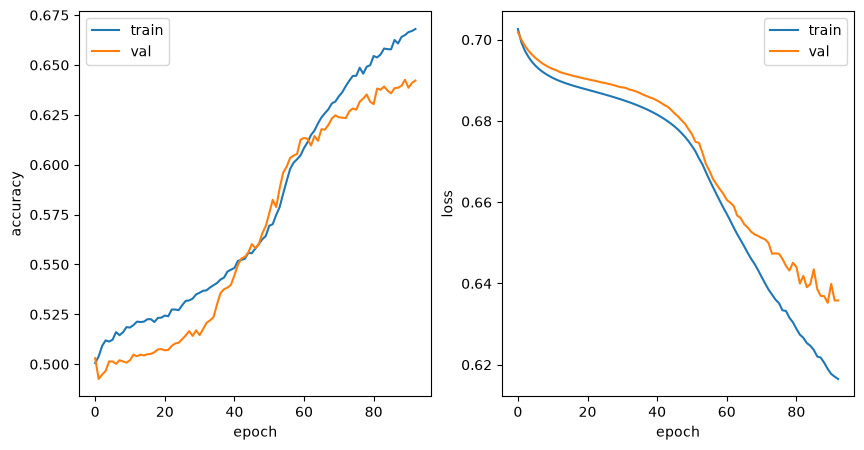

In [10]:
plot_history(history)